# A simple variational quantum algorithm: QAOA

## The problem

Given a graph, split its nodes into two groups so that as many edges as possible connect one group to the other. An edge that crosses between the groups is **cut**. This is **Max-Cut**. Checking every split costs $2^n$ for $n$ nodes, and no known classical algorithm solves Max-Cut exactly in time that grows only polynomially with the graph size. The **Quantum Approximate Optimization Algorithm (QAOA)** is a quantum heuristic that looks for a good (not always perfect) split.

## From a graph to a Hamiltonian

Give each node a qubit. Qubit $i$ in $|0\rangle$ or $|1\rangle$ means node $i$ is in group 0 or group 1. The edge $(i,j)$ is cut when the two qubits differ, which is when $Z_iZ_j = -1$. So the number of cut edges is

$$\text{cut}(z) = \sum_{(i,j)\in E} \frac{1 - Z_iZ_j}{2}.$$

QAOA minimizes an energy, so we use the **cost Hamiltonian** $H_C = -\text{cut}$:

$$H_C = \sum_{(i,j)\in E} \frac{Z_iZ_j - 1}{2}.$$

$H_C$ is diagonal: every bitstring is an eigenstate whose energy is minus its cut size. The ground state is therefore the best cut, and $E_0 = -(\text{max cut})$. Unlike the VQE example (`vqa.ipynb`), we are not after the energy itself: we want the **bitstring**.

## How it works

QAOA is a variational algorithm with a fixed, problem-shaped ansatz. Start in the uniform superposition $|+\rangle^{\otimes n}$, then repeat $p$ times:

1. **Cost layer** $e^{-i\gamma H_C}$. Gives each bitstring a phase proportional to its energy. On hardware it is one $R_{ZZ}(\gamma)$ gate per edge.
2. **Mixer layer** $e^{-i\beta \sum_i X_i}$. Moves amplitude between bitstrings. It is one $R_X(2\beta)$ gate per qubit.

The $2p$ angles $(\gamma_1,\ldots,\gamma_p,\beta_1,\ldots,\beta_p)$ are the variational parameters. A classical optimizer tunes them to minimize $\langle H_C\rangle$, exactly as in VQE. Then we **sample** the final circuit: the bitstrings it returns are candidate cuts, and we keep the best one.

```
(gamma, beta) --> [ H, then p x (cost, mixer) ] --> [ measure <H_C> ]
      ^                                                    |
      +--------------- optimizer updates angles <----------+

      best angles --> [ same circuit + measure all ] --> bitstrings
```

## What this notebook explores

We run QAOA on a small graph with **one layer ($p=1$)** and **two layers ($p=2$)** and compare how well each one converges and what the final samples look like. We also map out the energy landscape for $p=1$, and at the end we run on IBM hardware.

> **Things to keep in mind.** The number of layers $p$ sets the quality. Raising $p$ can only help in the ideal case (as $p$ grows, QAOA can approach the exact answer), but each layer adds two-qubit gates, which are the noisiest operations on hardware. The angle landscape has many local minima, so the starting point matters. And a good *average* sample is not the same as a good *best* sample: you only need the optimum to appear among your shots.

## Setup

By default this notebook runs only on the noiseless Aer simulator. To also run on IBM hardware, set `skip_hardware=False` below (you need a saved token; see `00-Setup-Start-Here`). Hardware jobs may wait in a queue.

The other settings:

- `graph`: which graph to solve, `"ring"` or `"house"` (see Step 1).
- `maxiter`: the maximum number of COBYLA iterations (each one is one energy evaluation, so one Estimator job).
- `starts`: how many random starting angles to try for each $p$. The best run is kept (see Step 5).
- `hardware_mode`: how to submit the hardware jobs, `"job"` or `"session"` (see Step 8).
- `grid`: how many values of $\gamma$ and $\beta$ to scan in the landscape plot (Step 4).

In [1]:
import itertools
import sys
import time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_ibm_runtime import EstimatorV2 as RuntimeEstimator
from qiskit_ibm_runtime import SamplerV2 as RuntimeSampler
from qiskit_ibm_runtime import Session
from scipy.optimize import minimize

# _common.py (in ../scripts) connects to IBM hardware.
# Run this notebook from its own folder (the default in Jupyter and VS Code).
# The next line looks for _common.py in ../scripts.
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
from _common import connect

SETTINGS = SimpleNamespace(
    shots=4096,
    backend="ibm_rensselaer",
    name="default",                       # saved IBM account name
    skip_hardware=True,                   # set to False to also run on IBM hardware
    hardware_mode="session",              # "job" or "session"
)

graph = "ring"   # "ring" or "house"
maxiter = 100     # COBYLA iterations (one energy evaluation each)
starts = 3        # random starting angles to try for each p
grid = 25         # points per axis in the p = 1 landscape scan
seed = 1          # random seed for the starting angles

OPTIMIZATION_LEVEL = 3
# Colors are a colorblind-safe pair: one color per number of layers p.
REPS_COLOR = {1: "#0072B2", 2: "#D55E00"}

## Background: Max-Cut (no graph theory required)

Step 1 introduces two graphs. Here is what the problem is, starting from nothing.

### Cutting a graph in two

A **graph** is a set of dots (**nodes**) joined by lines (**edges**). Color each node red or blue. An edge is **cut** when its two ends have different colors. Max-Cut asks: *which coloring cuts the most edges?* It shows up whenever you want to separate things that conflict, for example splitting a set of people into two teams so that as many known rivals as possible end up on opposite sides.

### Why some graphs can't be fully cut

On the **ring** (a square), color the nodes in alternating red and blue and every edge is cut. Now look at the **house**: a square with a triangular roof. Pick any coloring of a triangle, and two of its three corners must share a color, so at least one triangle edge stays uncut. The best the house can do is 5 of its 6 edges. That tension is called **frustration**, and it is what makes the problem hard in general.

### How the picture maps onto this notebook

| Graph | In the notebook / on hardware |
|---|---|
| Node | One qubit (qubit `i` of the circuit, placed on one physical qubit by the transpiler) |
| Node color red / blue | The qubit's value $|0\rangle$ / $|1\rangle$. A coloring is a bitstring, and Qiskit prints it with qubit 0 on the *right*. |
| Edge | A $Z_iZ_j$ term in $H_C$, and one $R_{ZZ}$ gate per layer in the circuit |
| Number of cut edges | $-$ the energy of that bitstring. `cut_value` counts it classically. |
| Best coloring | The ground state of $H_C$. `exact_max_cut` finds it by brute force, which is only possible because $n$ is small. |
| Measuring the energy | The Estimator measures every $Z_iZ_j$ term (Step 4). All of them are diagonal, so one readout basis serves every edge. |
| Noise | Each edge costs one $R_{ZZ}$ per layer, which becomes two CX gates on hardware. A graph with more edges, or a larger $p$, means a deeper and noisier circuit. |

The figure below shows both graphs with a best cut highlighted.

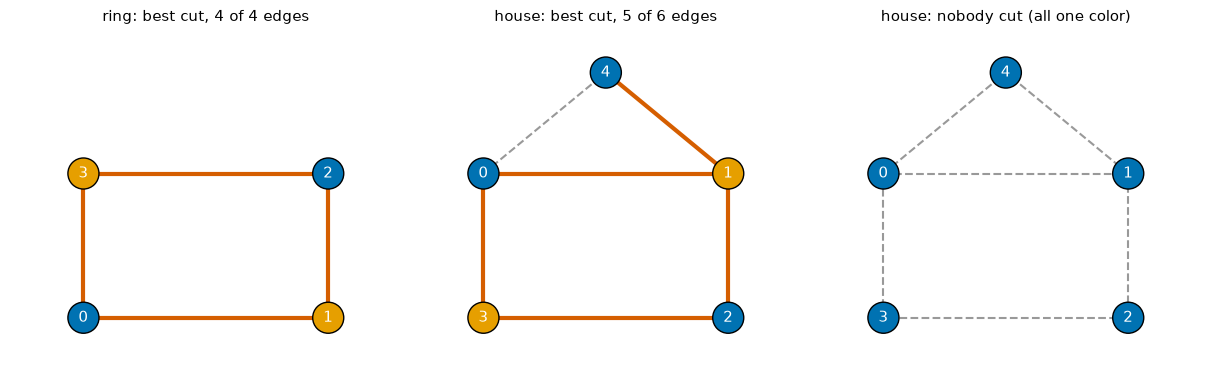

In [2]:
import networkx as nx

# Each graph is (number of nodes, list of edges).
GRAPHS = {
    # A square: bipartite, so every edge can be cut (max cut 4).
    "ring": (4, [(0, 1), (1, 2), (2, 3), (3, 0)]),
    # A square with a triangular roof: the triangle can never be fully cut,
    # so the best cut leaves one edge uncut (max cut 5 of 6).
    "house": (5, [(0, 1), (1, 2), (2, 3), (3, 0), (0, 4), (1, 4)]),
}
# Node positions for drawing only.
POSITIONS = {
    "ring": {0: (0, 0), 1: (1, 0), 2: (1, 1), 3: (0, 1)},
    "house": {0: (0, 1), 1: (1, 1), 2: (1, 0), 3: (0, 0), 4: (0.5, 1.7)},
}
# One best coloring of each graph, as a bitstring with node 0 on the left.
BEST_COLORING = {"ring": "0101", "house": "01010"}


def draw_graph(ax, name, coloring=None, title=None):
    # Draw a graph; cut edges are solid and orange, uncut edges are dashed gray.
    _, edges = GRAPHS[name]
    g = nx.Graph(edges)
    colors = ["#0072B2" if (coloring or "0" * len(g))[v] == "0" else "#E69F00" for v in g]
    cut = [e for e in edges if coloring and coloring[e[0]] != coloring[e[1]]]
    uncut = [e for e in edges if e not in cut]
    nx.draw_networkx_edges(g, POSITIONS[name], edgelist=cut, ax=ax, width=3, edge_color="#D55E00")
    nx.draw_networkx_edges(g, POSITIONS[name], edgelist=uncut, ax=ax, width=1.5,
                           edge_color="0.6", style="dashed")
    nx.draw_networkx_nodes(g, POSITIONS[name], ax=ax, node_color=colors, node_size=500,
                           edgecolors="black")
    nx.draw_networkx_labels(g, POSITIONS[name], ax=ax, font_color="white", font_size=11)
    ax.set_title(title or name, fontsize=11)
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylim(-0.3, 2.0)
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
draw_graph(axes[0], "ring", BEST_COLORING["ring"], "ring: best cut, 4 of 4 edges")
draw_graph(axes[1], "house", BEST_COLORING["house"], "house: best cut, 5 of 6 edges")
draw_graph(axes[2], "house", "00000", "house: nobody cut (all one color)")
plt.show()

## Step 1: The graph and its cost Hamiltonian

`maxcut_hamiltonian` turns the edge list into $H_C = \sum_{(i,j)} (Z_iZ_j - 1)/2$. Each edge gives one Pauli term $\tfrac12 Z_iZ_j$, plus a constant $-\tfrac12$ per edge that we collect in the identity term. Qiskit writes a Pauli string with qubit 0 on the *right*, so the helper reverses the label before building each term.

Because $H_C$ is diagonal, we can also find the answer by brute force. `cut_value` counts the cut edges of one bitstring, and `exact_max_cut` tries all $2^n$. This is the reference QAOA is trying to reach.

In [3]:
def maxcut_hamiltonian(num_nodes, edges):
    terms = []
    for i, j in edges:
        label = ["I"] * num_nodes
        label[i] = label[j] = "Z"
        terms.append(("".join(reversed(label)), 0.5))  # qubit 0 is rightmost
    terms.append(("I" * num_nodes, -0.5 * len(edges)))
    return SparsePauliOp.from_list(terms)


def cut_value(bits, edges):
    # Node i is the i-th bit from the right.
    group = bits[::-1]
    return sum(group[i] != group[j] for i, j in edges)


def exact_max_cut(num_nodes, edges):
    return max(
        cut_value("".join(map(str, bits)), edges)
        for bits in itertools.product([0, 1], repeat=num_nodes)
    )


num_nodes, edges = GRAPHS[graph]
hamiltonian = maxcut_hamiltonian(num_nodes, edges)
max_cut = exact_max_cut(num_nodes, edges)

print(f"{graph} graph: {num_nodes} nodes, {len(edges)} edges")
print("Cost Hamiltonian as Pauli terms:")
print(hamiltonian)
print(f"\nmax cut = {max_cut}, so the exact ground-state energy is E_0 = {-max_cut:+.4f}")
print(f"a random split cuts {len(edges) / 2:.1f} edges on average")

ring graph: 4 nodes, 4 edges
Cost Hamiltonian as Pauli terms:
SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'ZIIZ', 'IIII'],
              coeffs=[ 0.5+0.j,  0.5+0.j,  0.5+0.j,  0.5+0.j, -2. +0.j])

max cut = 4, so the exact ground-state energy is E_0 = -4.0000
a random split cuts 2.0 edges on average


The last line is the baseline to beat. Guessing a random split cuts half the edges on average, so a circuit that does no better than that has learned nothing. We call the ratio $\langle\text{cut}\rangle / \text{max cut}$ the **approximation ratio**, so random guessing scores 0.5 on the ring (2 of 4) and 0.5 on the house (3 of 6), and QAOA should beat it.

## Step 2: The QAOA circuit

The circuit is fixed by the problem, so unlike the VQE ansatzes there is nothing to design. `qaoa_circuit` builds the Hadamards, then `reps` (the $p$) repetitions of a cost layer and a mixer layer. All $2p$ angles live in one `ParameterVector`: the first `reps` are the cost angles $\gamma$, the last `reps` are the mixer angles $\beta$. The angles stay symbolic until we plug in numbers.

Two gate identities do the work:

- $R_{ZZ}(\gamma) = e^{-i\gamma Z_iZ_j/2}$, and $H_C$ has coefficient $\tfrac12$ on $Z_iZ_j$, so one `rzz(gamma)` per edge is $e^{-i\gamma H_C}$ up to a global phase that no measurement can see.
- $R_X(2\beta) = e^{-i\beta X}$, so one `rx(2*beta)` per qubit is the mixer.

No measurements are added: the Estimator measures $H_C$ itself. The barriers only mark where each layer starts in the drawing.

p = 1: 2 parameters
p = 2: 4 parameters


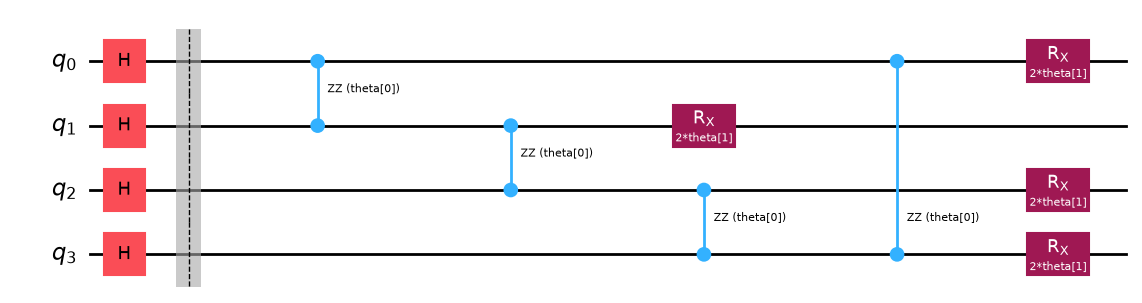

In [4]:
def qaoa_circuit(num_nodes, edges, reps):
    theta = ParameterVector("theta", 2 * reps)
    gamma, beta = theta[:reps], theta[reps:]
    circuit = QuantumCircuit(num_nodes, name=f"qaoa_p{reps}")
    circuit.h(range(num_nodes))
    for layer in range(reps):
        circuit.barrier()
        for i, j in edges:
            circuit.rzz(gamma[layer], i, j)
        for qubit in range(num_nodes):
            circuit.rx(2 * beta[layer], qubit)
    return circuit


circuits = {reps: qaoa_circuit(num_nodes, edges, reps) for reps in (1, 2)}
for reps, circuit in circuits.items():
    print(f"p = {reps}: {circuit.num_parameters} parameters")
circuits[1].draw("mpl")

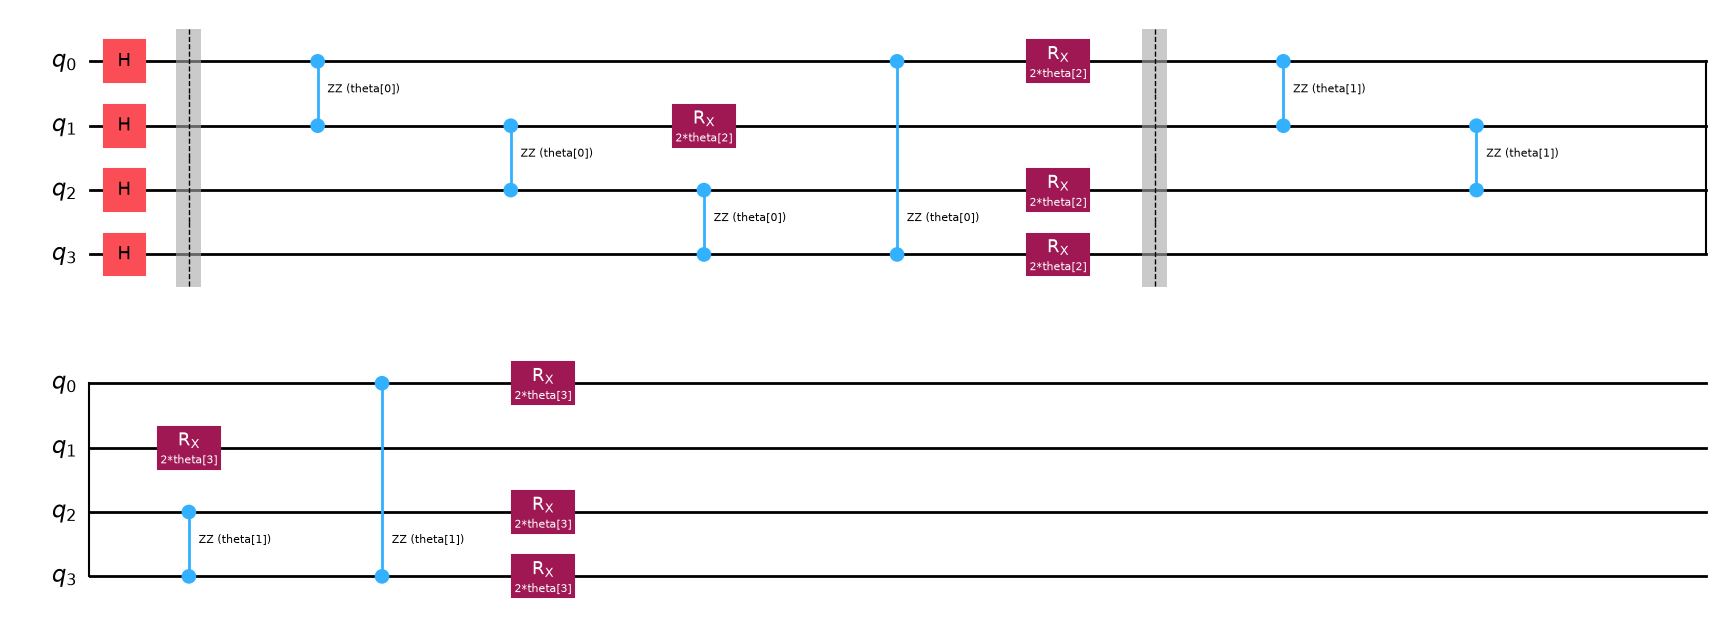

In [5]:
circuits[2].draw("mpl")

## Step 3: Transpile for the backend

Hardware only runs a small set of native gates on specific physical qubits. **Transpiling** picks which physical qubits the circuit uses (the *layout*) and rewrites every gate into the native gate set. For QAOA this means each $R_{ZZ}$ becomes two CX gates, so the two-qubit gate count is about twice the edge count per layer.

Two details matter, just as in VQE:

- The Hamiltonian is defined on the *logical* qubits $0, 1, \ldots$. After transpiling, those logical qubits may live on different physical qubits, so we must map the Hamiltonian onto the same layout with `apply_layout`. Otherwise the Estimator would measure the wrong qubits.
- The angles survive transpiling as symbolic parameters, so we transpile **once**, not once per optimizer step.

Here we transpile for the Aer simulator. The same function works unchanged for an IBM backend.

In [6]:
def transpile_problem(circuit, hamiltonian, pass_manager):
    isa_circuit = pass_manager.run(circuit)
    isa_hamiltonian = hamiltonian.apply_layout(isa_circuit.layout)
    print(
        f"  {circuit.name}: depth {isa_circuit.depth()}, "
        f"{isa_circuit.num_nonlocal_gates()} two-qubit gates"
    )
    return isa_circuit, isa_hamiltonian


aer = AerSimulator()
aer_pm = generate_preset_pass_manager(backend=aer, optimization_level=OPTIMIZATION_LEVEL)
print("Transpiled for the Aer simulator:")
for circuit in circuits.values():
    transpile_problem(circuit, hamiltonian, aer_pm)

Transpiled for the Aer simulator:
  qaoa_p1: depth 6, 4 two-qubit gates
  qaoa_p2: depth 11, 8 two-qubit gates


## Step 4: The cost function and its landscape

The cost function is the average energy $\langle H_C\rangle(\boldsymbol\theta) = -\langle\text{cut}\rangle$. We send the Estimator one PUB, a tuple of

`(circuit, observable, parameter values, precision)`

and it returns the expectation value (called `evs`). The Estimator takes a target **standard error** rather than a shot count. For a $\pm1$-valued observable after $N$ shots, the error is about $1/\sqrt N$, so that is the precision we request.

`make_primitives` returns the Aer Estimator and Sampler for the simulator, or the Runtime ones for IBM hardware. Both kinds are called the same way. We need the Sampler later, to read bitstrings from the final circuit.

For $p=1$ there are only two angles, so we can look at the whole landscape. One PUB can carry an *array* of parameter values, so the Estimator evaluates the entire grid in a single job.

  qaoa_p1: depth 6, 4 two-qubit gates
p = 1 landscape: 625 energies from one job
lowest energy on the grid: -3.016  (exact E_0 = -4.000)


energy with gamma = beta = 0 (no cost layer): -1.974


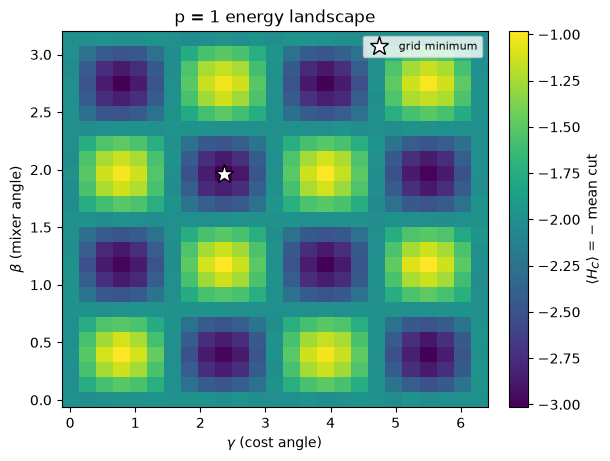

In [7]:
def make_primitives(backend, session=None):
    # session is an open Session (or None for "job mode"). Ignored on Aer.
    if isinstance(backend, AerSimulator):
        return AerEstimator(), AerSampler()
    mode = session if session is not None else backend
    return RuntimeEstimator(mode=mode), RuntimeSampler(mode=mode)


def energy(estimator, circuit, hamiltonian, values, shots):
    precision = 1 / np.sqrt(shots)
    job = estimator.run([(circuit, hamiltonian, values, precision)])
    return float(job.result()[0].data.evs)


estimator, sampler = make_primitives(aer)
isa_p1, isa_h = transpile_problem(circuits[1], hamiltonian, aer_pm)

# Scan gamma over [0, 2*pi) and beta over [0, pi) in ONE job.
gammas = np.linspace(0, 2 * np.pi, grid)
betas = np.linspace(0, np.pi, grid)
G, B = np.meshgrid(gammas, betas)
values = np.stack([G.ravel(), B.ravel()], axis=1)          # shape (grid*grid, 2)
precision = 1 / np.sqrt(SETTINGS.shots)
job = estimator.run([(isa_p1, isa_h, values, precision)])
landscape = job.result()[0].data.evs.reshape(grid, grid)

print(f"p = 1 landscape: {grid * grid} energies from one job")
print(f"lowest energy on the grid: {landscape.min():+.3f}  (exact E_0 = {-max_cut:+.3f})")
print(f"energy with gamma = beta = 0 (no cost layer): {energy(estimator, isa_p1, isa_h, np.zeros(2), SETTINGS.shots):+.3f}")

fig, ax = plt.subplots(figsize=(6, 4.5), constrained_layout=True)
mesh = ax.pcolormesh(G, B, landscape, shading="auto", cmap="viridis")
best = np.unravel_index(landscape.argmin(), landscape.shape)
ax.plot(gammas[best[1]], betas[best[0]], "w*", ms=14, mec="black", label="grid minimum")
fig.colorbar(mesh, ax=ax, label=r"$\langle H_C\rangle$ = $-$ mean cut")
ax.set(title="p = 1 energy landscape", xlabel=r"$\gamma$ (cost angle)", ylabel=r"$\beta$ (mixer angle)")
ax.legend(loc="upper right", fontsize=8)
plt.show()

With no cost layer ($\gamma=\beta=0$) the circuit only prepares $|+\rangle^{\otimes n}$, whose average cut is the random-guess baseline, half the edges. The valleys in the landscape are where the cost layer has steered amplitude toward better cuts. The pattern repeats because the angles are periodic, so the valleys are copies of each other and all are equally deep: any one of them is as good as another. For $p=1$ the optimizer therefore has an easy job. With more layers the landscape has more angles and genuinely different valleys, some deeper than others, which is why Step 5 tries several starting points.

## Step 5: The optimization loop

`run_qaoa` hands the cost function to **COBYLA**, a gradient-free optimizer. Gradient-free methods suit noisy energies because they only need function values. Every call to `cost` is one Estimator job, and the next angles depend on the last result. We record every energy it sees in `history`, plus the wall-clock time of the whole loop.

The landscape has several valleys, so one start can settle in a poor one. `best_of_starts` therefore runs the optimizer from `starts` random points and keeps the run with the lowest energy.

When the loop ends we need the *bitstrings*, not just the energy. `sample_counts` fixes the best angles, adds measurements to every qubit, and runs the Sampler. The circuit is transpiled again here because the Estimator version has no measurements. `summarize_counts` then reduces the counts to the numbers that matter:

- **approximation ratio**: the average cut of the samples divided by the max cut.
- **P(optimal)**: the fraction of shots that landed on a best cut. You only need one such shot to solve the problem.

In [8]:
def run_qaoa(estimator, circuit, hamiltonian, x0, shots, maxiter):
    history = []

    def cost(theta):
        history.append(energy(estimator, circuit, hamiltonian, theta, shots))
        return history[-1]

    start = time.perf_counter()
    result = minimize(cost, x0, method="COBYLA", options={"maxiter": maxiter})
    return {
        "history": history,
        "theta": result.x,
        "seconds": time.perf_counter() - start,
    }


def best_of_starts(estimator, circuit, hamiltonian, reps, shots, maxiter, starts):
    # Cost angles gamma first, then mixer angles beta.
    rng = np.random.default_rng(seed)
    runs = []
    for k in range(starts):
        x0 = np.concatenate([rng.uniform(0, np.pi, reps), rng.uniform(0, np.pi / 2, reps)])
        runs.append(run_qaoa(estimator, circuit, hamiltonian, x0, shots, maxiter))
        print(f"    start {k}: best <H_C> = {min(runs[-1]['history']):+.4f}")
    best = min(runs, key=lambda r: min(r["history"]))
    return {**best, "start_energies": [min(r["history"]) for r in runs]}


def sample_counts(sampler, circuit, theta, shots, pass_manager):
    measured = circuit.assign_parameters(theta)
    measured.measure_all()
    job = sampler.run([pass_manager.run(measured)], shots=shots)
    return job.result()[0].data.meas.get_counts()


def summarize_counts(counts, edges, max_cut):
    shots = sum(counts.values())
    cuts = {bits: cut_value(bits, edges) for bits in counts}
    mean_cut = sum(n * cuts[b] for b, n in counts.items()) / shots
    optimal = sum(n for b, n in counts.items() if cuts[b] == max_cut) / shots
    best_bits = max(counts, key=lambda b: (cuts[b], counts[b]))
    return {
        "mean_cut": mean_cut,
        "approx_ratio": mean_cut / max_cut,
        "p_optimal": optimal,
        "best_bits": best_bits,
        "best_cut": cuts[best_bits],
        "counts": counts,
        "cuts": cuts,
    }


def convergence_summary(history, max_cut):
    # A shallow circuit is not expected to reach E_0, so the gap is a quality
    # measure here, not a pass/fail test.
    return f"best <H_C> = {min(history):+.4f} (exact E_0 = {-max_cut:+.4f})"

## Step 6: Run p = 1 and p = 2

Now the experiment. For each $p$ we transpile once, run the loop from several random starting points on the noiseless Aer simulator, and then sample the best angles. The starting angles are drawn as $\gamma\in[0,\pi)$ and $\beta\in[0,\pi/2)$, with the cost angles first to match the `ParameterVector`. Results go into the `results` dictionary, keyed by mode and then by $p$, so we can compare them later against the hardware run.

In [9]:
results = {}   # mode -> {p: record}


records = {}
for reps, circuit in circuits.items():
    isa_circuit, isa_h = transpile_problem(circuit, hamiltonian, aer_pm)
    print(f"p = {reps}:")
    out = best_of_starts(estimator, isa_circuit, isa_h, reps, SETTINGS.shots, maxiter, starts)
    counts = sample_counts(sampler, circuit, out["theta"], SETTINGS.shots, aer_pm)
    stats = summarize_counts(counts, edges, max_cut)
    records[reps] = {"parameters": circuit.num_parameters, **out, **stats}
    print(f"  best start: {len(out['history'])} jobs in {out['seconds']:.1f} s; "
          + convergence_summary(out["history"], max_cut))
    print(f"  sampled mean cut {stats['mean_cut']:.3f} "
          f"(approximation ratio {stats['approx_ratio']:.3f}), "
          f"P(optimal cut) = {stats['p_optimal']:.3f}, "
          f"best sample {stats['best_bits']} cuts {stats['best_cut']} edges")
results["aer"] = records

  qaoa_p1: depth 6, 4 two-qubit gates
p = 1:


    start 0: best <H_C> = -3.0096


    start 1: best <H_C> = -2.9773


    start 2: best <H_C> = -3.0133
  best start: 34 jobs in 0.3 s; best <H_C> = -3.0133 (exact E_0 = -4.0000)
  sampled mean cut 3.008 (approximation ratio 0.752), P(optimal cut) = 0.536, best sample 0101 cuts 4 edges
  qaoa_p2: depth 11, 8 two-qubit gates
p = 2:


    start 0: best <H_C> = -3.2597


    start 1: best <H_C> = -3.5520


    start 2: best <H_C> = -3.5261
  best start: 44 jobs in 0.5 s; best <H_C> = -3.5520 (exact E_0 = -4.0000)
  sampled mean cut 3.540 (approximation ratio 0.885), P(optimal cut) = 0.783, best sample 0101 cuts 4 edges


## Step 7: Plot the results

Left: the energy the optimizer saw at each evaluation. The black line is the exact $E_0$. Right: how many shots of the final circuit landed on each cut size. A circuit that has learned the problem moves its weight to the right, toward the maximum cut.

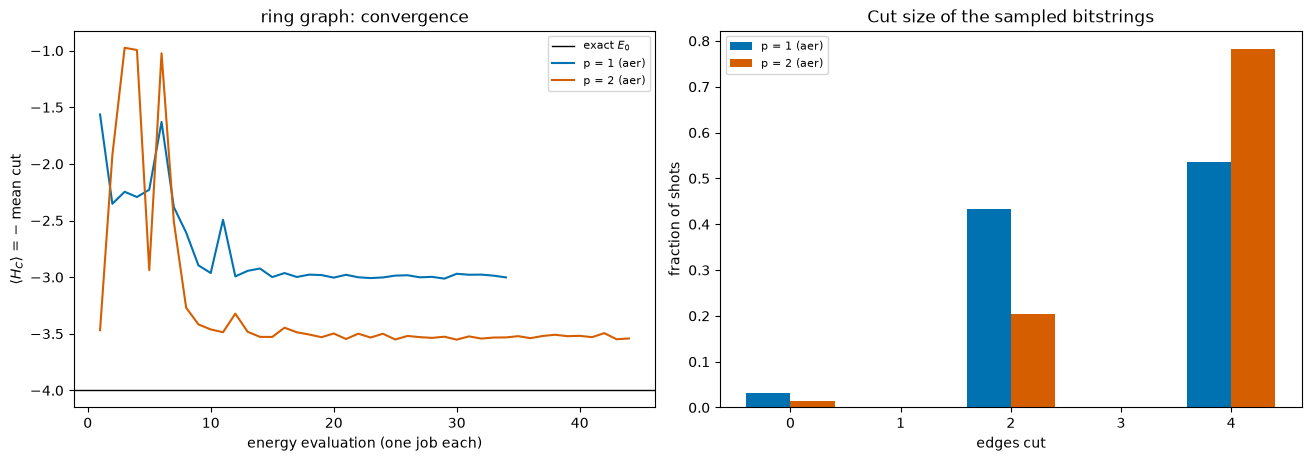

In [10]:
MODE_STYLE = {"aer": "-", "job": ":", "session": "--"}


def plot_results(results):
    fig, (ax_h, ax_c) = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

    # Left: energy per evaluation.
    ax_h.axhline(-max_cut, color="black", lw=1, label="exact $E_0$")
    for mode, recs in results.items():
        for reps, rec in recs.items():
            ax_h.plot(range(1, len(rec["history"]) + 1), rec["history"],
                      color=REPS_COLOR[reps], ls=MODE_STYLE[mode], lw=1.5,
                      label=f"p = {reps} ({mode})")
    ax_h.set(title=f"{graph} graph: convergence",
             xlabel="energy evaluation (one job each)",
             ylabel=r"$\langle H_C\rangle$ = $-$ mean cut")
    ax_h.legend(fontsize=8)

    # Right: distribution of cut sizes in the final samples.
    sizes = np.arange(max_cut + 1)
    runs = [(mode, reps, rec) for mode, recs in results.items() for reps, rec in recs.items()]
    width = 0.8 / len(runs)
    for k, (mode, reps, rec) in enumerate(runs):
        freq = np.zeros(len(sizes))
        for bits, n in rec["counts"].items():
            freq[rec["cuts"][bits]] += n
        ax_c.bar(sizes + (k - (len(runs) - 1) / 2) * width, freq / freq.sum(), width,
                 color=REPS_COLOR[reps], alpha=1.0 if mode == "aer" else 0.55,
                 label=f"p = {reps} ({mode})")
    ax_c.set(title="Cut size of the sampled bitstrings", xlabel="edges cut",
             ylabel="fraction of shots", xticks=sizes)
    ax_c.legend(fontsize=8)
    plt.show()


plot_results(results)

### Reading the plot

- **Convergence.** Neither curve reaches $E_0$ exactly, and that is expected: with only $p$ layers the circuit cannot put all of its weight on the best cuts. The $p=1$ curve flattens at the floor of the landscape you saw in Step 4. The $p=2$ curve ends clearly lower, because the extra layer gives the circuit more freedom. The printed start energies in Step 6 show that the $p=2$ starts did *not* all land in the same place, which is the starting-point sensitivity at work.
- **Samples.** On the ring, the $p=1$ circuit already beats random guessing, but a large share of its shots land on cuts that are not optimal. The $p=2$ circuit moves much more weight onto the largest cut. The exact numbers change with the seed.
- **Best sample vs average sample.** Even a mediocre average leaves some probability on the optimum. With thousands of shots, one of them is very likely to be a best cut, and `cut_value` lets us check it classically. This is how QAOA is used in practice: sample many bitstrings, score them, keep the best.

This is the central trade-off of QAOA: **quality** (more layers $p$ means better cuts) against **cost** (more angles to optimize, and more two-qubit gates to run).

## Step 8: Running on IBM hardware

The optimizer loop is a chain of dependent Estimator jobs: each new set of angles depends on the previous energy. How those jobs are grouped decides how long you wait in the queue.

| Mode | What it does | Fit for QAOA |
|---|---|---|
| **Job** (no context) | Each evaluation is queued on its own, so 40 steps can mean 40 waits. | Slowest |
| **Session** | Reserves the backend for you for the duration of the loop. Jobs start one after another with no new queue wait. | **The optimizer loop** |

The final sampling job runs inside the same mode. `vqa.ipynb` compares all three modes, including batch mode, in detail. Batch does not help here, since the optimizer loop is dependent, though it would suit screening many random starting angles up front.

On hardware, expect noise to lift the energies and lower the approximation ratio compared with Aer. $p=2$ has twice the two-qubit gates, so noise affects it more, and past some depth extra layers hurt rather than help.

The next cell runs only if `skip_hardware=False`.

In [11]:
def run_on_hardware(mode):
    backend = connect(SETTINGS.backend, SETTINGS.name)
    if backend is None:
        return None
    session = Session(backend=backend) if mode == "session" else None
    records = {}
    try:
        hw_estimator, hw_sampler = make_primitives(backend, session)
        hw_pm = generate_preset_pass_manager(
            backend=backend, optimization_level=OPTIMIZATION_LEVEL
        )
        for reps, circuit in circuits.items():
            isa_circuit, isa_h = transpile_problem(circuit, hamiltonian, hw_pm)
            print(f"p = {reps}:")
            out = best_of_starts(hw_estimator, isa_circuit, isa_h, reps,
                                 SETTINGS.shots, maxiter, starts)
            counts = sample_counts(hw_sampler, circuit, out["theta"], SETTINGS.shots, hw_pm)
            stats = summarize_counts(counts, edges, max_cut)
            records[reps] = {"parameters": circuit.num_parameters, **out, **stats}
            print(f"  best start: {len(out['history'])} jobs in {out['seconds']:.1f} s; "
                  + convergence_summary(out["history"], max_cut))
            print(f"  approximation ratio {stats['approx_ratio']:.3f}, "
                  f"P(optimal cut) = {stats['p_optimal']:.3f}")
    finally:
        if session is not None:
            session.close()
    return records


if SETTINGS.skip_hardware:
    print("skip_hardware=True: set it to False in Setup to run on IBM hardware.")
else:
    mode = SETTINGS.hardware_mode
    print(f"=== {graph}, {mode} mode on {SETTINGS.backend} ===")
    records = run_on_hardware(mode)
    if records is not None:
        results[mode] = records
        plot_results(results)

skip_hardware=True: set it to False in Setup to run on IBM hardware.


## Summary and things to try

- QAOA turns "find the best cut" into "minimize $\langle H_C\rangle(\boldsymbol\gamma,\boldsymbol\beta)$," then **samples** the tuned circuit to read off candidate answers.
- The circuit is dictated by the problem: one $R_{ZZ}$ per edge in the cost layer, one $R_X$ per qubit in the mixer. The only knob is the depth $p$.
- More layers give better cuts in principle, at the price of more angles, more iterations, and more two-qubit gates, which are the noisiest operations on hardware.
- On hardware, **session** mode suits the dependent jobs of the optimizer loop.

Try these:

1. Set `graph = "house"` and rerun. The triangle roof is frustrated, so the max cut is 5 of 6 edges. Does going from $p=1$ to $p=2$ help as much as it did on the ring? Compare the approximation ratios and `P(optimal cut)`.
2. Change `seed`, or set `starts = 1`, and rerun. How much do the final $p=2$ energies move? A single unlucky start can end well above the best one.
3. Add `3` to the circuits in Step 2 (`for reps in (1, 2, 3)`) and give it a color in `REPS_COLOR`. Does $p=3$ keep improving?
4. Lower `SETTINGS.shots` to 256. How does shot noise change the convergence curves and the landscape?
5. Add your own graph to `GRAPHS` (a triangle is `(3, [(0, 1), (1, 2), (2, 0)])`). Which graphs are easy and which are frustrated?
6. Set `skip_hardware=False` and compare `"job"` and `"session"` for a small `maxiter` such as 30.